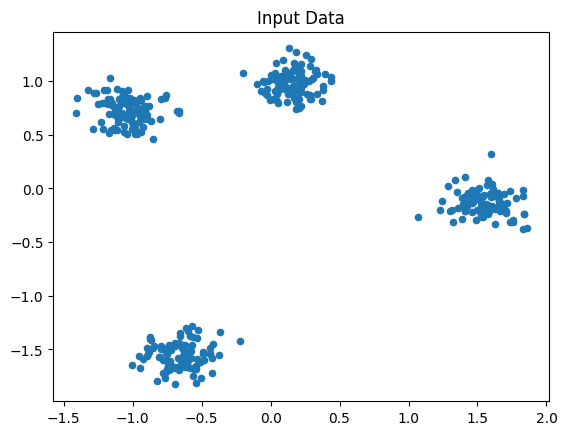

,k,inertia,silhouette
0,2,416.393903,0.573188
1,3,88.247963,0.768901
2,4,13.224550,0.850399
3,5,11.844380,0.712433
4,6,10.498762,0.583324
5,7,9.238124,0.454668
6,8,8.159860,0.340792
7,9,7.477716,0.345853


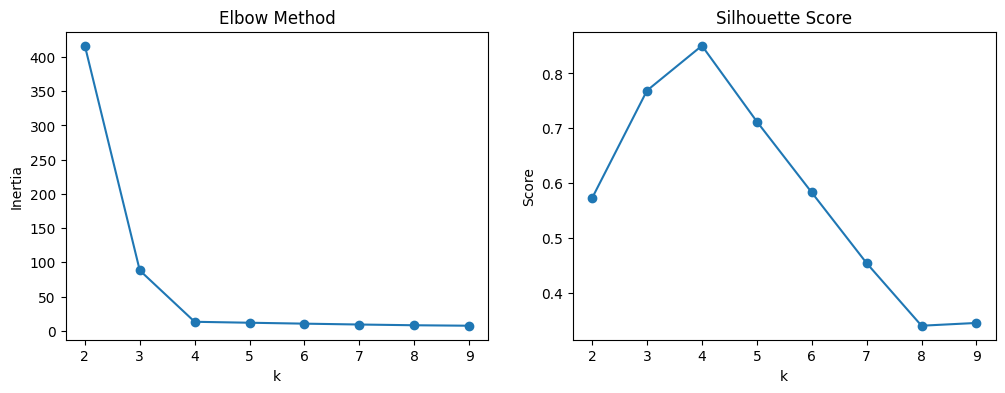

Chosen k: 4
Silhouette score: 0.8503991071555768


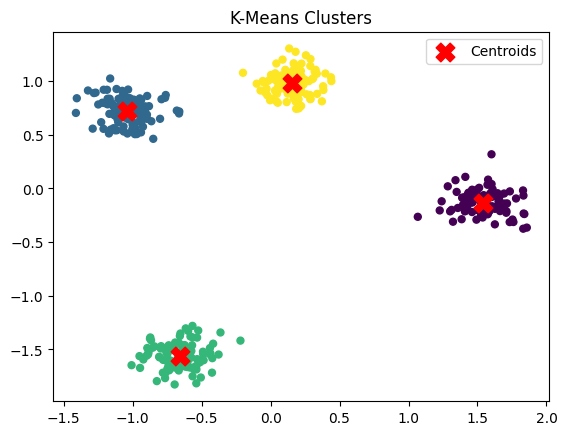

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X, _ = make_blobs(n_samples=400, centers=4, cluster_std=0.75, random_state=42)
X_scaled = StandardScaler().fit_transform(X)
plt.scatter(X_scaled[:,0], X_scaled[:,1], s=20)
plt.title("Input Data")
plt.show()

ks = range(2,10)
inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))
display(pd.DataFrame({"k":list(ks), "inertia":inertias, "silhouette":silhouettes}))

fig, ax = plt.subplots(1,2,figsize=(12,4))
ax[0].plot(list(ks), inertias, marker="o")
ax[0].set(title="Elbow Method", xlabel="k", ylabel="Inertia")
ax[1].plot(list(ks), silhouettes, marker="o")
ax[1].set(title="Silhouette Score", xlabel="k", ylabel="Score")
plt.show()

chosen_k = 4  # Justify this choice using the plots above
kmeans = KMeans(n_clusters=chosen_k, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_scaled)
print("Chosen k:", chosen_k)
print("Silhouette score:", silhouette_score(X_scaled, labels))

plt.scatter(X_scaled[:,0], X_scaled[:,1], c=labels, cmap="viridis", s=25)
plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1],
            c="red", marker="X", s=180, label="Centroids")
plt.title("K-Means Clusters")
plt.legend()
plt.show()